# Ajuste de hiperparámetros de modelos de ML con algoritmos genéticos
### Tutorial práctico basado en el Capítulo 8 de *Hands-On Genetic Algorithms with Python*

## ¿Qué ejercicio se desarrolla en el capítulo 8?

El capítulo resuelve **un único problema** con tres enfoques distintos:

> Encontrar la mejor combinación de **tres hiperparámetros** de un clasificador **AdaBoost** (`n_estimators`, `learning_rate`, `algorithm`) para clasificar el **dataset Wine** de UCI (178 vinos, 13 mediciones químicas, 3 clases), usando como criterio la **exactitud (accuracy) media en validación cruzada**.

| # | Enfoque | Qué hace |
|---|---------|----------|
| 1 | **Grid search convencional** | Prueba exhaustivamente las 200 combinaciones de una rejilla (10 × 10 × 2). |
| 2 | **Grid search guiado por un AG** | Busca dentro de la *misma* rejilla, pero evaluando solo una fracción de las combinaciones. |
| 3 | **AG directo** | Busca en el espacio continuo completo, sin estar limitado a los valores de la rejilla. Cada hiperparámetro se codifica como un `float`. |

La tesis del capítulo: el enfoque 2 alcanza el mismo resultado que el 1 en menos tiempo, y el enfoque 3 puede superarlos porque no está atado a la rejilla.

## Requisitos previos

El capítulo **asume** (sin explicarlos) estos conocimientos:

- **Python básico:** clases, listas, diccionarios, funciones.
- **Algoritmos genéticos con DEAP** (capítulos anteriores): individuo/cromosoma, población, función de aptitud, selección por torneo, cruce, mutación, elitismo y *Hall of Fame* (HOF), el objeto `toolbox` y `creator`.
- **Aprendizaje supervisado** (capítulo 7): clasificación, exactitud y validación cruzada *k-fold*.
- **Optimización de funciones con `float`** (capítulo 6): cruce `cxSimulatedBinaryBounded` y mutación `mutPolynomialBounded`.

El capítulo además **usa sin mostrar** tres piezas que aquí sí se incluyen: el módulo `elitism.py` (capítulo 3), la carga de Wine y del esquema de validación cruzada (capítulo 7), y las constantes del AG directo (tamaño de población, probabilidades, etc.).

## Estructura del notebook

1. Importaciones y adaptaciones respecto al libro
2. Conceptos: hiperparámetros y grid search
3. Dataset Wine y clasificador AdaBoost
4. Infraestructura genética (elitismo, `creator`)
5. Experimentos 1-3: rendimiento por defecto, grid search, grid search genético
6. Experimento 4: AG directo con representación en `float`
7. Comparación final y gráficas
8. Conclusiones

## Adaptaciones respecto al libro

Para que el notebook sea ejecutable de principio a fin se hicieron estos cambios. Cada uno queda también señalado con un comentario en el código.

| Tema | En el libro | En este notebook | Motivo |
|------|-------------|------------------|--------|
| Carga de Wine | CSV desde el repositorio UCI | `sklearn.datasets.load_wine` | Es el mismo dataset (178 × 13, 3 clases) y evita depender de la red. |
| `algorithm='SAMME.R'` | Se usa sin más | Se exige `scikit-learn < 1.6` | `SAMME.R` quedó obsoleto en la 1.4 y **se eliminó en la 1.6**. Sin él, el hiperparámetro categórico del ejercicio dejaría de tener dos valores. |
| Grid search genético | `EvolutionaryAlgorithmSearchCV` de `sklearn-deap` | Implementación propia con DEAP (misma idea) | `sklearn-deap` no se mantiene y falla con versiones modernas de scikit-learn. La implementación propia hace visible qué ocurre dentro. |
| Nombre de método | `convertParam()` en el texto, `convertParams()` en el código | `convertParams()` | Errata del libro. |
| Rango de `learning_rate` | "entre 0.1 (10⁻²) y 1" | Entre **0.01** (10⁻²) y 1 | Errata: 10⁻² vale 0.01, y `np.logspace(-2, 0)` genera de 0.01 a 1. |
| Constructor del clasificador en `getAccuracy` | Sin `random_state` | Con `random_state` | Hace la evaluación reproducible: el mismo individuo da siempre la misma aptitud. |
| Módulo `elitism.py` | Importado, no mostrado | Función `eaSimpleWithElitism` incluida | El notebook debe ser autocontenido. |
| Esquema de validación cruzada | No se muestra | `RepeatedStratifiedKFold(n_splits=5, n_repeats=1)` | Decisión propia (equilibrio entre fiabilidad y tiempo). |

> **Sobre los números:** el libro no muestra el esquema de validación cruzada ni la versión de scikit-learn que usó. Por eso **tus valores exactos pueden diferir** de los del libro. Tras cada experimento se indican los valores de referencia del libro y, sobre todo, **qué patrón cualitativo debes observar**.

## 1. Importaciones

Bibliotecas usadas en todo el notebook:

- **`numpy`, `pandas`, `matplotlib`**: cálculo, tablas y gráficas.
- **`scikit-learn`** (versión < 1.6): dataset, clasificador AdaBoost, validación cruzada y grid search.
- **`deap`**: la maquinaria de algoritmos genéticos.

Si no las tienes, instálalas **antes** de importar (y reinicia el kernel si scikit-learn ya estaba cargado):

```
pip install deap numpy pandas matplotlib "scikit-learn>=1.2,<1.6"
```

In [ ]:
pip install deap numpy pandas matplotlib "scikit-learn>=1.2,<1.6"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 25.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 24.7 MB/s  0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [deap]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [ ]:
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn import datasets, model_selection
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV

from deap import base, creator, tools, algorithms

# scikit-learn 1.4 y 1.5 avisan de que 'SAMME.R' quedará obsoleto; silenciamos solo ese aviso.
warnings.filterwarnings("ignore", category=FutureWarning)

# Comprobación de compatibilidad: 'SAMME.R' desapareció en scikit-learn 1.6.
sklearnVersion = tuple(int(p) for p in sklearn.__version__.split(".")[:2])
assert sklearnVersion < (1, 6), (
    f"Tienes scikit-learn {sklearn.__version__}. Este ejercicio necesita algorithm='SAMME.R', "
    "eliminado en la 1.6. Ejecuta: pip install 'scikit-learn<1.6' y reinicia el kernel."
)

print("scikit-learn:", sklearn.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)

scikit-learn: 1.5.2
numpy: 2.1.3
pandas: 2.2.3


## 2. Hiperparámetros y grid search

Un modelo de aprendizaje supervisado tiene dos tipos de parámetros:

- **Parámetros internos:** los ajusta el algoritmo de aprendizaje durante el entrenamiento (por ejemplo, los pesos de una red).
- **Hiperparámetros:** se fijan **antes** de entrenar y condicionan *cómo* se aprende (profundidad máxima de un árbol, número de estimadores, etc.). Tienen valores por defecto, pero su elección afecta mucho al rendimiento.

Buscar buenas combinaciones de hiperparámetros se llama **ajuste de hiperparámetros** (*hyperparameter tuning*). Las técnicas que cubre el capítulo:

- **Grid search:** eliges un subconjunto de valores por hiperparámetro y pruebas **todas** las combinaciones. Su problema es el coste: crece multiplicativamente con cada hiperparámetro.
- **Random search:** prueba combinaciones al azar (se menciona, pero no se usa).
- **Grid search genético:** un AG recorre la misma rejilla buscando las mejores combinaciones sin probarlas todas.
- **AG directo:** el AG busca en todo el espacio de parámetros, sin rejilla.

## 3. El dataset Wine y el clasificador AdaBoost

**Wine** (UCI) contiene el análisis químico de **178 vinos** de una misma región de Italia, clasificados en **3 tipos**. Hay **13 mediciones** por vino: alcohol, ácido málico, ceniza, alcalinidad de la ceniza, magnesio, fenoles totales, flavonoides, fenoles no flavonoides, proantocianinas, intensidad de color, tono, OD280/OD315 y prolina.

**AdaBoost** (*adaptive boosting*) combina mediante una suma ponderada las salidas de muchos clasificadores simples ("aprendices débiles"). Va añadiendo aprendices, cada uno ajustado para corregir las entradas que los anteriores clasificaron mal. Los tres hiperparámetros que se ajustan son de **tres tipos distintos**, y eso es lo interesante del ejercicio:

| Nombre | Tipo | Descripción | Valor por defecto |
|--------|------|-------------|-------------------|
| `n_estimators` | `int` | Número máximo de estimadores | 50 |
| `learning_rate` | `float` | Reduce la contribución de cada clasificador | 1.0 |
| `algorithm` | categórico `{'SAMME', 'SAMME.R'}` | `SAMME.R`: boosting real; `SAMME`: boosting discreto | `'SAMME.R'` |

Echemos un vistazo rápido a los datos.

In [ ]:
wine = datasets.load_wine()
dfWine = pd.DataFrame(wine.data, columns=wine.feature_names)
dfWine["clase"] = wine.target

print("Forma de X:", wine.data.shape)
print("Muestras por clase:")
print(dfWine["clase"].value_counts().sort_index().to_string())
dfWine.head()

Forma de X: (178, 13)
Muestras por clase:
clase
0    59
1    71
2    48


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


**Salida esperada:** `Forma de X: (178, 13)`, con 59, 71 y 48 vinos en las clases 0, 1 y 2, y una tabla con las 13 columnas más `clase`. (El libro numera las clases como 1, 2 y 3; `load_wine` las numera 0, 1 y 2. No afecta a nada.)

## 4. Preparación común: dataset, clasificador y validación cruzada

El libro repite la misma inicialización en dos clases distintas. Aquí la agrupamos en una **clase base**, `WineAdaBoostBase`, de la que heredan las dos clases del capítulo. Contiene:

- `initWineDataset()`: carga `X` (13 columnas) e `y` (tipo de vino).
- `initClassifier()`: crea un AdaBoost con sus hiperparámetros por defecto. Fijamos `random_state` para que los resultados sean repetibles.
- `initKfold()`: define la validación cruzada. Usamos **5 particiones estratificadas** (cada partición conserva la proporción de clases). Como `random_state` es un entero, **las particiones son siempre las mismas**: eso es crucial, porque todas las combinaciones de hiperparámetros deben compararse sobre los mismos datos.

> **Por qué validación cruzada y no una sola partición:** con solo 178 muestras, una única división entrenamiento/prueba daría una exactitud muy dependiente del azar. La media sobre 5 particiones es una medida de aptitud mucho más estable.

In [ ]:
RANDOM_SEED = 42


class WineAdaBoostBase:
    """Inicialización común: dataset Wine, clasificador AdaBoost y validación cruzada."""

    def __init__(self, randomSeed):
        self.randomSeed = randomSeed
        self.initWineDataset()
        self.initClassifier()
        self.initKfold()

    def initWineDataset(self):
        # Equivalente al CSV de UCI del libro: 178 filas x 13 características.
        self.X, self.y = datasets.load_wine(return_X_y=True)

    def initClassifier(self):
        # Hiperparámetros por defecto: n_estimators=50, learning_rate=1.0, algorithm='SAMME.R'
        self.classifier = AdaBoostClassifier(random_state=self.randomSeed)

    def initKfold(self):
        # Mismas particiones en cada llamada (random_state entero) -> comparación justa.
        self.kfold = model_selection.RepeatedStratifiedKFold(
            n_splits=5, n_repeats=1, random_state=self.randomSeed)

## 5. Infraestructura genética compartida

Los dos enfoques genéticos usan las mismas piezas. Las definimos una sola vez.

**a) Fitness e individuo.** El objetivo es **maximizar** la exactitud, así que usamos `FitnessMax` con peso `1.0`. Un individuo es simplemente una `list` con fitness asociado. Esa misma clase sirve para el grid genético (lista de índices enteros) y para el AG directo (lista de `float`).

**b) Algoritmo con elitismo (`elitism.py` del libro).** Es el `eaSimple` de DEAP con un cambio: en cada generación, los miembros del *Hall of Fame* (los mejores individuos hasta el momento) pasan **intactos** a la siguiente generación. Así el mejor resultado encontrado nunca se pierde por culpa de un cruce o una mutación desafortunados. Ese es el enfoque elitista que menciona el capítulo (paso 9).

**c) Mutación sobre índices.** Para el grid genético, cada gen es un **índice** dentro de la lista de valores de un hiperparámetro. La mutación sustituye, con una probabilidad por gen, ese índice por otro válido al azar.

In [ ]:
creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)


def eaSimpleWithElitism(population, toolbox, cxpb, mutpb, ngen, stats=None,
                        halloffame=None, verbose=__debug__):
    """Como algorithms.eaSimple, pero los miembros del Hall of Fame pasan intactos
    a la siguiente generación (elitismo)."""
    logbook = tools.Logbook()
    logbook.header = ["gen", "nevals"] + (stats.fields if stats else [])

    # Evaluar los individuos sin aptitud válida
    invalidInd = [ind for ind in population if not ind.fitness.valid]
    fitnesses = toolbox.map(toolbox.evaluate, invalidInd)
    for ind, fit in zip(invalidInd, fitnesses):
        ind.fitness.values = fit

    if halloffame is None:
        raise ValueError("El parámetro halloffame no puede estar vacío")

    halloffame.update(population)
    hofSize = len(halloffame.items) if halloffame.items else 0

    record = stats.compile(population) if stats else {}
    logbook.record(gen=0, nevals=len(invalidInd), **record)
    if verbose:
        print(logbook.stream)

    for gen in range(1, ngen + 1):
        # Seleccionar menos individuos: los huecos los ocupará la élite
        offspring = toolbox.select(population, len(population) - hofSize)
        offspring = algorithms.varAnd(offspring, toolbox, cxpb, mutpb)

        invalidInd = [ind for ind in offspring if not ind.fitness.valid]
        fitnesses = toolbox.map(toolbox.evaluate, invalidInd)
        for ind, fit in zip(invalidInd, fitnesses):
            ind.fitness.values = fit

        # Reinsertar la élite sin modificar
        offspring.extend(halloffame.items)
        halloffame.update(offspring)
        population[:] = offspring

        record = stats.compile(population) if stats else {}
        logbook.record(gen=gen, nevals=len(invalidInd), **record)
        if verbose:
            print(logbook.stream)

    return population, logbook


def mutateIndices(individual, maxints, indpb):
    """Mutación para genes que son índices: con probabilidad indpb, cada gen pasa a un índice
    válido aleatorio (entre 0 y maxints[i])."""
    for i, upper in enumerate(maxints):
        if random.random() < indpb:
            individual[i] = random.randint(0, upper)
    return individual,

## 6. La clase `HyperparameterTuningGrid` (enfoques 1 y 2)

Hereda de `WineAdaBoostBase` y reproduce la clase del libro. Sus métodos, en el orden del capítulo:

1. **`initGridParams()`** define la rejilla: 10 valores de `n_estimators` (de 10 a 100), 10 valores de `learning_rate` espaciados **logarítmicamente** entre 0.01 y 1, y los 2 valores de `algorithm`. En total, **10 × 10 × 2 = 200 combinaciones**. Se usa escala logarítmica porque `learning_rate` actúa de forma multiplicativa: la diferencia entre 0.01 y 0.1 importa más que entre 0.9 y 1.0.
2. **`getDefaultAccuracy()`** mide la exactitud media (validación cruzada) con los hiperparámetros por defecto. Es la línea base.
3. **`gridTest()`** hace el grid search convencional con `GridSearchCV`: entrena y evalúa las 200 combinaciones.
4. **`geneticGridTest()`** hace el grid search genético. Aquí está la idea central:
   - **Representación:** un individuo es una lista de **3 índices**, uno por hiperparámetro, p. ej. `[6, 5, 1]` significa "séptimo valor de `n_estimators`, sexto de `learning_rate`, segundo de `algorithm`". Los máximos son `[9, 9, 1]` (es lo que el libro muestra como `maxint [9, 9, 1]`).
   - **Aptitud:** exactitud media en validación cruzada de la combinación que representa el individuo. Se guarda en una **caché**: si un individuo repetido vuelve a aparecer, no se reentrena. Por eso el número de evaluaciones reales es menor que el tamaño de la población multiplicado por las generaciones.
   - **Operadores:** selección por torneo (tamaño 2), cruce de dos puntos y la mutación por índices anterior.
   - **Parámetros del capítulo:** población 20, probabilidad de mutación por gen 0.30, torneo 2 y 5 generaciones. El capítulo no indica las probabilidades de cruce y mutación a nivel de individuo; usamos 0.5 y 0.5.
   - **Criterio de parada:** un número fijo de generaciones. Es simple, predecible en tiempo y suficiente para una rejilla de solo 200 puntos.

> **Alternativa del libro (no usada aquí):** el capítulo llama a `EvolutionaryAlgorithmSearchCV` de la biblioteca `sklearn-deap`, con los mismos parámetros:
> ```python
> EvolutionaryAlgorithmSearchCV(estimator=..., params=gridParams, cv=kfold, scoring='accuracy',
>                               verbose=True, population_size=20, gene_mutation_prob=0.30,
>                               tournament_size=2, generations_number=5)
> ```
> Nuestra implementación hace lo mismo en espíritu, pero con DEAP directamente.

In [ ]:
class HyperparameterTuningGrid(WineAdaBoostBase):
    """Grid search convencional y grid search guiado por un algoritmo genético."""

    def __init__(self, randomSeed):
        super().__init__(randomSeed)
        self.initGridParams()

    def initGridParams(self):
        self.gridParams = {
            "n_estimators": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
            # 10 valores en escala logarítmica de 10**-2 = 0.01 a 10**0 = 1
            # (el texto del libro dice "0.1 (10^-2)": errata, el mínimo es 0.01)
            "learning_rate": np.logspace(-2, 0, num=10, base=10),
            "algorithm": ["SAMME", "SAMME.R"],
        }

    def getDefaultAccuracy(self):
        cvResults = model_selection.cross_val_score(
            self.classifier, self.X, self.y, cv=self.kfold, scoring="accuracy")
        return cvResults.mean()

    def gridTest(self):
        """Grid search exhaustivo sobre las 200 combinaciones."""
        gridSearch = GridSearchCV(estimator=self.classifier,
                                  param_grid=self.gridParams,
                                  cv=self.kfold,
                                  scoring="accuracy")
        start = time.time()
        gridSearch.fit(self.X, self.y)
        elapsed = time.time() - start
        return {"bestParams": gridSearch.best_params_,
                "bestScore": gridSearch.best_score_,
                "elapsed": elapsed,
                "evaluations": len(gridSearch.cv_results_["params"]),
                "cvResults": pd.DataFrame(gridSearch.cv_results_)}

    def geneticGridTest(self, populationSize=20, geneMutationProb=0.30, tournamentSize=2,
                        generationsNumber=5, cxpb=0.5, mutpb=0.5, hofSize=1):
        """Grid search guiado por un AG: cada individuo es una lista de índices de la rejilla."""
        names = list(self.gridParams.keys())
        values = [list(self.gridParams[n]) for n in names]
        maxints = [len(v) - 1 for v in values]
        print(f"maxint {maxints} detectado -> {np.prod([len(v) for v in values])} combinaciones posibles")

        scoreCache = {}

        def decode(individual):
            params = {}
            for name, vals, idx in zip(names, values, individual):
                v = vals[idx]
                params[name] = float(v) if isinstance(v, np.floating) else v
            return params

        def evaluate(individual):
            key = tuple(individual)
            if key not in scoreCache:  # solo se entrena si la combinación es nueva
                model = clone(self.classifier).set_params(**decode(individual))
                scores = model_selection.cross_val_score(
                    model, self.X, self.y, cv=self.kfold, scoring="accuracy")
                scoreCache[key] = scores.mean()
            return scoreCache[key],

        toolbox = base.Toolbox()
        for k, upper in enumerate(maxints):
            toolbox.register(f"gene_{k}", random.randint, 0, upper)
        genes = tuple(getattr(toolbox, f"gene_{k}") for k in range(len(maxints)))
        toolbox.register("individualCreator", tools.initCycle, creator.Individual, genes, n=1)
        toolbox.register("populationCreator", tools.initRepeat, list, toolbox.individualCreator)
        toolbox.register("evaluate", evaluate)
        toolbox.register("select", tools.selTournament, tournsize=tournamentSize)
        toolbox.register("mate", tools.cxTwoPoint)
        toolbox.register("mutate", mutateIndices, maxints=maxints, indpb=geneMutationProb)

        stats = tools.Statistics(lambda ind: ind.fitness.values)
        stats.register("avg", np.mean)
        stats.register("min", np.min)
        stats.register("max", np.max)
        stats.register("std", np.std)

        random.seed(self.randomSeed)
        population = toolbox.populationCreator(n=populationSize)
        hof = tools.HallOfFame(hofSize)

        start = time.time()
        population, logbook = eaSimpleWithElitism(
            population, toolbox, cxpb=cxpb, mutpb=mutpb, ngen=generationsNumber,
            stats=stats, halloffame=hof, verbose=True)
        elapsed = time.time() - start

        best = hof.items[0]
        return {"bestParams": decode(best),
                "bestScore": best.fitness.values[0],
                "elapsed": elapsed,
                "evaluations": len(scoreCache),
                "logbook": logbook}

In [ ]:
gridTuner = HyperparameterTuningGrid(RANDOM_SEED)

totalCombinations = int(np.prod([len(v) for v in gridTuner.gridParams.values()]))
print("Combinaciones en la rejilla:", totalCombinations)
print("Valores de learning_rate:", np.round(gridTuner.gridParams["learning_rate"], 4))

Combinaciones en la rejilla: 200
Valores de learning_rate: [0.01   0.0167 0.0278 0.0464 0.0774 0.1292 0.2154 0.3594 0.5995 1.    ]


**Salida esperada:** `Combinaciones en la rejilla: 200` y los 10 valores de `learning_rate`: `0.01, 0.0167, 0.0278, 0.0464, 0.0774, 0.1292, 0.2154, 0.3594, 0.5995, 1.0`.

## 7. Experimento 1: rendimiento con los hiperparámetros por defecto

Primero, la **línea base**: ¿qué exactitud da AdaBoost sin ajustar nada (`n_estimators=50`, `learning_rate=1.0`, `algorithm='SAMME.R'`)?

In [ ]:
defaultParams = {k: gridTuner.classifier.get_params()[k]
                 for k in ("n_estimators", "learning_rate", "algorithm")}
defaultAccuracy = gridTuner.getDefaultAccuracy()

print("Hiperparámetros por defecto:", defaultParams)
print("Exactitud con valores por defecto =", defaultAccuracy)

Hiperparámetros por defecto: {'n_estimators': 50, 'learning_rate': 1.0, 'algorithm': 'SAMME.R'}
Exactitud con valores por defecto = 0.8641269841269841


**Referencia del libro:** `{'algorithm': 'SAMME.R', 'learning_rate': 1.0, 'n_estimators': 50}` con una exactitud de **0.6457** (≈ 65 %), que el libro califica como "no particularmente buena".

**Qué debes observar:** los hiperparámetros por defecto son los indicados. La exactitud exacta depende del esquema de validación cruzada y de la versión de scikit-learn, y puede ser bastante distinta del 65 % del libro. Lo importante es que este valor es la **línea base** que los métodos de ajuste deberían igualar o mejorar.

## 8. Experimento 2: grid search convencional

Se entrenan y evalúan las **200 combinaciones**. Además de la mejor, mostramos las 5 primeras de la tabla de resultados para ver lo plano o puntiagudo que es el paisaje de búsqueda.

In [ ]:
gridResult = gridTuner.gridTest()

print("Mejores parámetros:", gridResult["bestParams"])
print("Mejor puntuación:", gridResult["bestScore"])
print("Combinaciones evaluadas:", gridResult["evaluations"])
print(f"Tiempo = {gridResult['elapsed']:.2f} s")

topGrid = (gridResult["cvResults"]
           .sort_values("rank_test_score")
           .head(5)[["param_n_estimators", "param_learning_rate", "param_algorithm", "mean_test_score"]])
topGrid

Mejores parámetros: {'algorithm': 'SAMME', 'learning_rate': np.float64(0.5994842503189409), 'n_estimators': 80}
Mejor puntuación: 0.954920634920635
Combinaciones evaluadas: 200
Tiempo = 132.76 s


,param_n_estimators,param_learning_rate,param_algorithm,mean_test_score
87,80,0.599484,SAMME,0.954921
86,70,0.599484,SAMME,0.954762
71,20,0.359381,SAMME,0.949365
84,50,0.599484,SAMME,0.949206
91,20,1.000000,SAMME,0.949206


**Referencia del libro:** mejor combinación `n_estimators = 70`, `learning_rate ≈ 0.359`, `algorithm = 'SAMME.R'`, exactitud **0.9326** (≈ 93 %), 200 combinaciones evaluadas, unos **32 s**.

**Qué debes observar:** una exactitud **claramente superior** a la línea base y 200 combinaciones evaluadas. Anota el tiempo: es el punto de comparación para el grid genético.

## 9. Experimento 3: grid search guiado por un algoritmo genético

Misma rejilla, pero ahora el AG decide qué combinaciones merece la pena evaluar. La salida muestra, por generación: número de evaluaciones de individuos (`nevals`) y estadísticas de aptitud (media, mínimo, máximo y desviación).

Observa que `nevals` es menor que 20 a partir de la generación 1: los individuos que sobreviven sin cambios conservan su aptitud y no se reevalúan.

In [ ]:
geneticGridResult = gridTuner.geneticGridTest(
    populationSize=20, geneMutationProb=0.30, tournamentSize=2, generationsNumber=5)

print("\nMejor individuo:", geneticGridResult["bestParams"])
print("con aptitud:", geneticGridResult["bestScore"])
print("Combinaciones distintas realmente entrenadas:", geneticGridResult["evaluations"], "de", totalCombinations)
print(f"Tiempo = {geneticGridResult['elapsed']:.2f} s")

maxint [9, 9, 1] detectado -> 200 combinaciones posibles
gen	nevals	avg     	min     	max     	std      
0  	20    	0.898413	0.686032	0.949206	0.0755916
1  	12    	0.925817	0.83619 	0.954921	0.0289111
2  	16    	0.911484	0.686032	0.954921	0.0585761
3  	12    	0.926016	0.830476	0.954921	0.0314147
4  	11    	0.935524	0.841746	0.954921	0.0241795
5  	11    	0.942913	0.932063	0.954921	0.00694347

Mejor individuo: {'n_estimators': 80, 'learning_rate': 0.5994842503189409, 'algorithm': 'SAMME'}
con aptitud: 0.954920634920635
Combinaciones distintas realmente entrenadas: 53 de 200
Tiempo = 29.92 s


**Referencia del libro:** el AG encontró la **misma mejor combinación** que el grid exhaustivo (`n_estimators = 70`, `learning_rate ≈ 0.359`, `SAMME.R`, aptitud 0.9326) en unos **11 s** frente a 32 s. La aptitud media por generación sube de ≈ 0.64 a ≈ 0.91 y el máximo de ≈ 0.90 a 0.9326.

**Qué debes observar:**
- La columna `avg` **crece** de generación en generación y `max` **no decrece nunca** (efecto del elitismo).
- El número de combinaciones realmente entrenadas es **muy inferior a 200**, por lo que el tiempo baja.
- La mejor aptitud debería **igualar o acercarse mucho** a la del grid exhaustivo. Es un método estocástico: si no coincide exactamente, prueba otra semilla (`RANDOM_SEED`) o más generaciones (`generationsNumber=8`).

> **Matiz del libro:** en este ejemplo el ahorro es modesto porque el problema es pequeño. En problemas reales (datos grandes, modelos costosos, rejillas enormes) un grid exhaustivo puede ser prohibitivo, y ahí el grid genético es una alternativa viable.

## 10. Experimento 4: AG directo sobre el espacio de hiperparámetros

Los grid searches, genéticos o no, están **limitados a los valores de la rejilla**. Ahora el AG busca directamente en el espacio continuo, sin rejilla.

### 10.1 Representación: todo como `float`

Los tres hiperparámetros tienen tipos distintos (entero, real, categórico). El libro propone un enfoque "perezoso" pero eficaz: **representar los tres como `float`** y reutilizar los operadores de optimización continua del capítulo 6. Se necesita una transformación de ida y vuelta:

| Hiperparámetro | Rango del `float` | Conversión al valor real |
|----------------|-------------------|--------------------------|
| `n_estimators` (int) | [1, 100] | `round(x)` |
| `learning_rate` (float) | [0.01, 1.0] | ninguna |
| `algorithm` (categórico) | [0, 1] | `round(x)` da 0 o 1 → `'SAMME'` o `'SAMME.R'` |

**Por qué funciona:** al redondear, cada entero o categoría corresponde a un intervalo del espacio continuo, así que los operadores continuos siguen siendo válidos. **Contrapartida:** muchos valores `float` distintos producen el mismo clasificador (hay "mesetas"), y el AG puede evaluar varias veces lo que en la práctica es lo mismo.

### 10.2 La clase `HyperparameterTuningGenetic`

Encapsula la **función de aptitud**:

- **`convertParams(params)`**: recibe la lista de 3 `float` y devuelve los valores reales (esta es la transformación de la tabla).
- **`getAccuracy(params)`**: convierte, construye un `AdaBoostClassifier` con esos valores y devuelve su exactitud media en validación cruzada. Es la aptitud del individuo.

In [ ]:
class HyperparameterTuningGenetic(WineAdaBoostBase):
    """Evalúa la exactitud de AdaBoost para un individuo representado como lista de 3 floats."""

    def convertParams(self, params):
        # (el libro lo llama convertParam en el texto y convertParams en el código)
        nEstimators = round(params[0])                      # float -> int
        learningRate = params[1]                            # ya es float
        algorithm = ["SAMME", "SAMME.R"][round(params[2])]  # float -> categoría
        return nEstimators, learningRate, algorithm

    def getAccuracy(self, params):
        nEstimators, learningRate, algorithm = self.convertParams(params)
        # random_state añadido: el mismo individuo debe dar siempre la misma aptitud
        self.classifier = AdaBoostClassifier(n_estimators=nEstimators,
                                             learning_rate=learningRate,
                                             algorithm=algorithm,
                                             random_state=self.randomSeed)
        cvResults = model_selection.cross_val_score(
            self.classifier, self.X, self.y, cv=self.kfold, scoring="accuracy")
        return cvResults.mean()


test = HyperparameterTuningGenetic(RANDOM_SEED)

# Prueba rápida de la conversión (n_estimators=69.4 -> 69, algoritmo 0.8 -> 'SAMME.R')
print(test.convertParams([69.4, 0.628, 0.8]))

(69, 0.628, 'SAMME.R')


**Salida esperada:** `(69, 0.628, 'SAMME.R')`.

### 10.3 Constantes del algoritmo y justificación

El capítulo indica solo la población (20) y el número de generaciones (5). El resto son los valores habituales de los capítulos anteriores, que el capítulo no lista.

- **`BOUNDS_LOW` / `BOUNDS_HIGH`:** límites de cada `float` según la tabla anterior.
- **`POPULATION_SIZE = 20`, `MAX_GENERATIONS = 5`:** presupuesto reducido a propósito. Cada evaluación entrena un AdaBoost con validación cruzada, que es la parte cara. **Este es el criterio de parada:** un número fijo de generaciones.
- **`P_CROSSOVER = 0.9`, `P_MUTATION = 0.5`:** cruce frecuente y mutación moderada para explorar sin destruir las buenas soluciones.
- **`HALL_OF_FAME_SIZE = 5`:** las 5 mejores soluciones pasan intactas a cada generación (elitismo).
- **`CROWDING_FACTOR = 20.0`:** parámetro `eta` de los operadores de cruce y mutación acotados; valores altos generan hijos más parecidos a los padres (búsqueda más local).

In [ ]:
# [n_estimators, learning_rate, algorithm]
BOUNDS_LOW = [1, 0.01, 0]
BOUNDS_HIGH = [100, 1.00, 1]
NUM_OF_PARAMS = len(BOUNDS_HIGH)

POPULATION_SIZE = 20
P_CROSSOVER = 0.9
P_MUTATION = 0.5
MAX_GENERATIONS = 5
HALL_OF_FAME_SIZE = 5
CROWDING_FACTOR = 20.0

### 10.4 Construcción del toolbox

1. **Un generador por hiperparámetro.** Como cada gen tiene un rango distinto, registramos un operador `hyperparameter_i` con `random.uniform(BOUNDS_LOW[i], BOUNDS_HIGH[i])` por cada uno (paso 4 del libro).
2. **Individuo.** `tools.initCycle` llama una vez a cada generador (`n=1`) y construye la lista `[n_estimators, learning_rate, algorithm]` (pasos 5 y 6).
3. **Aptitud.** Usa `getAccuracy`. DEAP exige que devuelva una tupla, de ahí la coma final (paso 7).
4. **Operadores** (paso 8):
   - **Selección:** torneo de tamaño 2, simple y con presión selectiva moderada.
   - **Cruce:** `cxSimulatedBinaryBounded`, especializado en listas de `float` con límites **distintos por gen**.
   - **Mutación:** `mutPolynomialBounded`, con `indpb = 1/3` (en promedio, un gen por individuo).

In [ ]:
toolbox = base.Toolbox()

# Un generador de floats por hiperparámetro: "hyperparameter_0", "hyperparameter_1", ...
for i in range(NUM_OF_PARAMS):
    toolbox.register("hyperparameter_" + str(i),
                     random.uniform, BOUNDS_LOW[i], BOUNDS_HIGH[i])

hyperparameters = tuple(getattr(toolbox, "hyperparameter_" + str(i))
                        for i in range(NUM_OF_PARAMS))

toolbox.register("individualCreator", tools.initCycle,
                 creator.Individual, hyperparameters, n=1)
toolbox.register("populationCreator", tools.initRepeat, list, toolbox.individualCreator)


def classificationAccuracy(individual):
    return test.getAccuracy(individual),


toolbox.register("evaluate", classificationAccuracy)
toolbox.register("select", tools.selTournament, tournsize=2)
toolbox.register("mate", tools.cxSimulatedBinaryBounded,
                 low=BOUNDS_LOW, up=BOUNDS_HIGH, eta=CROWDING_FACTOR)
toolbox.register("mutate", tools.mutPolynomialBounded,
                 low=BOUNDS_LOW, up=BOUNDS_HIGH, eta=CROWDING_FACTOR,
                 indpb=1.0 / NUM_OF_PARAMS)

### 10.5 Ejecución

Se crea la población inicial, se registran estadísticas (máximo y media por generación) y se lanza el algoritmo con elitismo (paso 9). Fija la semilla para que la ejecución sea reproducible.

In [ ]:
random.seed(RANDOM_SEED)
population = toolbox.populationCreator(n=POPULATION_SIZE)

stats = tools.Statistics(lambda ind: ind.fitness.values)
stats.register("max", np.max)
stats.register("avg", np.mean)

hof = tools.HallOfFame(HALL_OF_FAME_SIZE)

start = time.time()
population, logbook = eaSimpleWithElitism(
    population, toolbox, cxpb=P_CROSSOVER, mutpb=P_MUTATION,
    ngen=MAX_GENERATIONS, stats=stats, halloffame=hof, verbose=True)
directElapsed = time.time() - start

best = hof.items[0]
bestNEstimators, bestLearningRate, bestAlgorithm = test.convertParams(best)
print("\n- Mejor solución:")
print(f"params = 'n_estimators'= {bestNEstimators}, 'learning_rate'={bestLearningRate:.3f}, 'algorithm'={bestAlgorithm}")
print("Exactitud =", best.fitness.values[0])
print(f"Tiempo = {directElapsed:.2f} s")

gen	nevals	max     	avg     
0  	20    	0.949206	0.928071
1  	13    	0.954921	0.945603
2  	14    	0.954921	0.947516
3  	14    	0.954921	0.946159
4  	15    	0.955079	0.944492
5  	13    	0.955079	0.947849

- Mejor solución:
params = 'n_estimators'= 20, 'learning_rate'=0.732, 'algorithm'=SAMME.R
Exactitud = 0.9550793650793651
Tiempo = 62.60 s


**Referencia del libro:** tras 5 generaciones con población 20, el máximo pasó de 0.9213 a 0.9492 y la media de 0.841 a 0.939. La mejor solución fue `n_estimators = 69`, `learning_rate = 0.628`, `algorithm = 'SAMME.R'`, exactitud **0.94921** (≈ 94.9 %), **mejor que el grid search** (≈ 93 %).

**Qué debes observar:**
- `max` **no baja** y `avg` **sube**: el AG converge.
- La mejor exactitud **iguala o supera** la del grid search, porque el AG explora valores que la rejilla no contiene.
- El libro destaca que `n_estimators` (69) y `learning_rate` (0.628) quedaron **fuera de los valores de la rejilla**. Lo comprobamos a continuación.

In [ ]:
gridNEstimators = gridTuner.gridParams["n_estimators"]
gridLearningRates = gridTuner.gridParams["learning_rate"]

nEstimatorsInGrid = bestNEstimators in gridNEstimators
learningRateInGrid = bool(np.isclose(bestLearningRate, gridLearningRates).any())

print(f"n_estimators = {bestNEstimators} ¿está en la rejilla? {nEstimatorsInGrid}")
print(f"learning_rate = {bestLearningRate:.3f} ¿está en la rejilla? {learningRateInGrid}")
print(f"Mejora del AG directo sobre el grid search: {best.fitness.values[0] - gridResult['bestScore']:+.4f}")

n_estimators = 20 ¿está en la rejilla? True
learning_rate = 0.732 ¿está en la rejilla? False
Mejora del AG directo sobre el grid search: +0.0002


**Qué debes observar:** lo normal es que al menos uno de los dos valores (casi con seguridad `learning_rate`, que es continuo) **no esté en la rejilla**. Si el AG directo no supera al grid en tu ejecución, repite con otra semilla o más generaciones: es un método estocástico y con solo 5 generaciones la variabilidad es alta.

## 11. Comparación final

Reunimos los cuatro resultados en una tabla y los visualizamos: (1) comparación de exactitud, (2) curvas de convergencia de los dos AG y (3) dónde cae cada solución dentro del espacio de hiperparámetros.

In [ ]:
directEvaluations = int(sum(logbook.select("nevals")))

summary = pd.DataFrame([
    {"método": "Valores por defecto", "exactitud": defaultAccuracy, "tiempo (s)": np.nan,
     "evaluaciones": 1,
     "parámetros": "n_estimators=50, learning_rate=1.0, SAMME.R"},
    {"método": "Grid search (exhaustivo)", "exactitud": gridResult["bestScore"],
     "tiempo (s)": gridResult["elapsed"], "evaluaciones": gridResult["evaluations"],
     "parámetros": str({k: (round(v, 3) if isinstance(v, float) else v)
                        for k, v in gridResult["bestParams"].items()})},
    {"método": "Grid search genético", "exactitud": geneticGridResult["bestScore"],
     "tiempo (s)": geneticGridResult["elapsed"], "evaluaciones": geneticGridResult["evaluations"],
     "parámetros": str({k: (round(v, 3) if isinstance(v, float) else v)
                        for k, v in geneticGridResult["bestParams"].items()})},
    {"método": "AG directo (floats)", "exactitud": best.fitness.values[0],
     "tiempo (s)": directElapsed, "evaluaciones": directEvaluations,
     "parámetros": f"n_estimators={bestNEstimators}, learning_rate={bestLearningRate:.3f}, {bestAlgorithm}"},
])
summary.round({"exactitud": 4, "tiempo (s)": 1})

,método,exactitud,tiempo (s),evaluaciones,parámetros
0,Valores por defecto,0.8641,NaN,1,"n_estimators=50, learning_rate=1.0, SAMME.R"
1,Grid search (exhaustivo),0.9549,132.8,200,"{'algorithm': 'SAMME', 'learning_rate': np.flo..."
2,Grid search genético,0.9549,29.9,53,"{'n_estimators': 80, 'learning_rate': 0.599, '..."
3,AG directo (floats),0.9551,62.6,89,"n_estimators=20, learning_rate=0.732, SAMME.R"


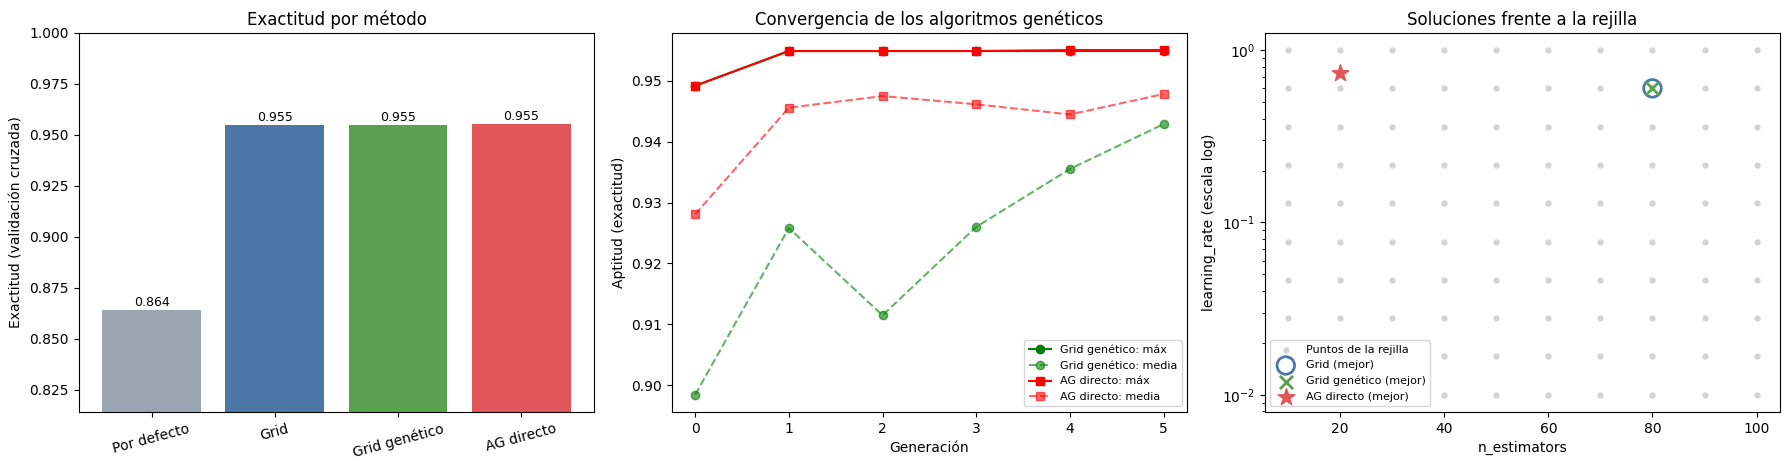

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# (1) Exactitud por método
labels = ["Por defecto", "Grid", "Grid genético", "AG directo"]
accs = summary["exactitud"].values
bars = axes[0].bar(labels, accs, color=["#9aa5b1", "#4c78a8", "#59a14f", "#e15759"])
axes[0].set_ylim(max(0, accs.min() - 0.05), 1.0)
axes[0].set_ylabel("Exactitud (validación cruzada)")
axes[0].set_title("Exactitud por método")
axes[0].tick_params(axis="x", rotation=15)
for b, a in zip(bars, accs):
    axes[0].text(b.get_x() + b.get_width() / 2, a + 0.002, f"{a:.3f}", ha="center", fontsize=9)

# (2) Convergencia de ambos AG
gridLog = geneticGridResult["logbook"]
axes[1].plot(gridLog.select("gen"), gridLog.select("max"), "g-o", label="Grid genético: máx")
axes[1].plot(gridLog.select("gen"), gridLog.select("avg"), "g--o", alpha=0.6, label="Grid genético: media")
axes[1].plot(logbook.select("gen"), logbook.select("max"), "r-s", label="AG directo: máx")
axes[1].plot(logbook.select("gen"), logbook.select("avg"), "r--s", alpha=0.6, label="AG directo: media")
axes[1].set_xlabel("Generación")
axes[1].set_ylabel("Aptitud (exactitud)")
axes[1].set_title("Convergencia de los algoritmos genéticos")
axes[1].legend(fontsize=8)

# (3) Espacio de hiperparámetros: rejilla vs. soluciones encontradas
gx, gy = np.meshgrid(gridNEstimators, gridLearningRates)
axes[2].scatter(gx.ravel(), gy.ravel(), s=12, c="lightgray", label="Puntos de la rejilla")
axes[2].scatter(gridResult["bestParams"]["n_estimators"], gridResult["bestParams"]["learning_rate"],
                s=160, facecolors="none", edgecolors="#4c78a8", linewidths=2, label="Grid (mejor)")
axes[2].scatter(geneticGridResult["bestParams"]["n_estimators"],
                geneticGridResult["bestParams"]["learning_rate"],
                s=90, marker="x", c="#59a14f", linewidths=2, label="Grid genético (mejor)")
axes[2].scatter(bestNEstimators, bestLearningRate, s=160, marker="*", c="#e15759", label="AG directo (mejor)")
axes[2].set_yscale("log")
axes[2].set_xlabel("n_estimators")
axes[2].set_ylabel("learning_rate (escala log)")
axes[2].set_title("Soluciones frente a la rejilla")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Qué debes observar en las gráficas:**
1. **Barras:** las tres técnicas de ajuste superan claramente a los valores por defecto; el AG directo queda igual o por encima de los grid searches.
2. **Convergencia:** las líneas de máximo son escalonadas y nunca descienden; las de media suben.
3. **Espacio de búsqueda:** las soluciones de los dos grid searches caen **sobre puntos grises** (están restringidas a la rejilla). La estrella roja del AG directo suele caer **entre** puntos.

## 12. Conclusiones

**Qué se logró**

- Se planteó el ajuste de hiperparámetros de AdaBoost sobre Wine como un problema de optimización con tres variables de tipos distintos (`int`, `float`, categórica).
- Se midió una **línea base** con los valores por defecto y se mejoró con tres métodos: grid search exhaustivo, grid search guiado por un AG y AG directo.
- Se vio cómo los AG convierten la búsqueda en un proceso guiado: la aptitud media sube generación tras generación y el elitismo garantiza que el mejor resultado no se pierde.

**Lo que debes ver al ejecutar el notebook**

| Comprobación | Resultado esperado |
|--------------|--------------------|
| Rejilla | 200 combinaciones (10 × 10 × 2) |
| Ajuste frente a línea base | Los tres métodos mejoran la exactitud por defecto (el libro: ≈ 65 % → ≈ 93-95 %) |
| Grid genético frente a exhaustivo | Aptitud igual o muy cercana, entrenando **bastantes menos** de 200 combinaciones |
| Convergencia | `max` no decrece nunca y `avg` crece en ambos AG |
| AG directo | Exactitud igual o superior a la del grid (el libro: 0.949 frente a 0.933) |
| Valores fuera de la rejilla | `learning_rate` (y, según la ejecución, `n_estimators`) no coincide con los valores de la rejilla |

**Lecciones de diseño del capítulo**

1. **Representar todo como `float` simplifica la implementación**, porque se reutilizan operadores acotados ya conocidos. A cambio aparecen mesetas: muchos genes distintos dan el mismo modelo.
2. **Un AG sobre una rejilla** reduce el coste sin cambiar la lista de candidatos. Un **AG directo** puede, además, superar los límites de la rejilla.
3. **La función de aptitud es la parte cara** (entrenar y validar). Por eso se usan poblaciones y generaciones pequeñas, y una caché cuando los individuos pueden repetirse.

**Cuidado con los resultados:** los algoritmos son estocásticos y con poblaciones de 20 individuos y 5 generaciones la variabilidad es notable. Si una ejecución concreta no cumple alguna de las comprobaciones, cambia `RANDOM_SEED`, aumenta `MAX_GENERATIONS` o `POPULATION_SIZE` y repite.